In [1]:
%pip install kagglehub


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%%writefile functions.py
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_confusion_map(y_true, y_pred, labels, title):
    """Show the confusion matrix as a heatmap (rows = true, columns = predicted)."""
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(matrix, annot=True, cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.show()

Overwriting functions.py


In [3]:
# Imports
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.metrics import accuracy_score, classification_report

from functions import plot_confusion_map

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# 1. Loading the data
path = kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data")
os.listdir(path)

['penguins_size.csv', 'penguins_lter.csv']

In [5]:
penguins = pd.read_csv(os.path.join(path, "penguins_size.csv"))
penguins.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [6]:
# 2. Cleaning: check shape, missing values, duplicates and invalid entries
print(penguins.shape)
print(penguins.isna().sum())
print(penguins.duplicated().sum())
print(penguins["sex"].value_counts())

(344, 7)
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
0
sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64


In [7]:
# Remove rows with missing values and the invalid "." in sex
# Result: 333 penguins. Classes are imbalanced: Adelie 44%, Gentoo 36%, Chinstrap 20%.
# Always guessing Adelie would already give 44% accuracy. That is our baseline.
penguins = penguins.dropna()
penguins = penguins[penguins["sex"] != "."]
print(penguins.shape)
penguins["species"].value_counts()

(333, 7)


species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

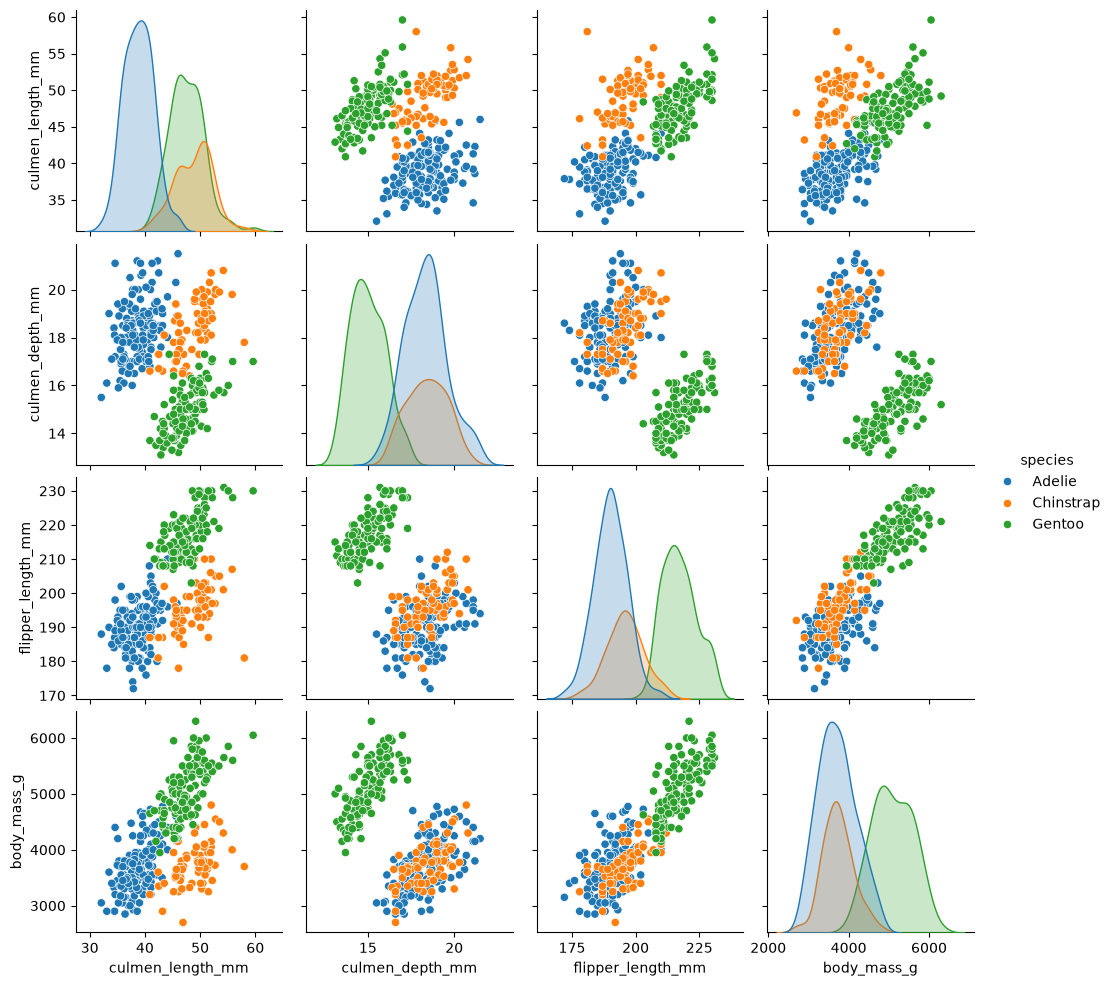

In [8]:
# 3. EDA: the pairplot shows three clear clusters, so the measurements separate the species well
sns.pairplot(penguins, hue="species")
plt.show()

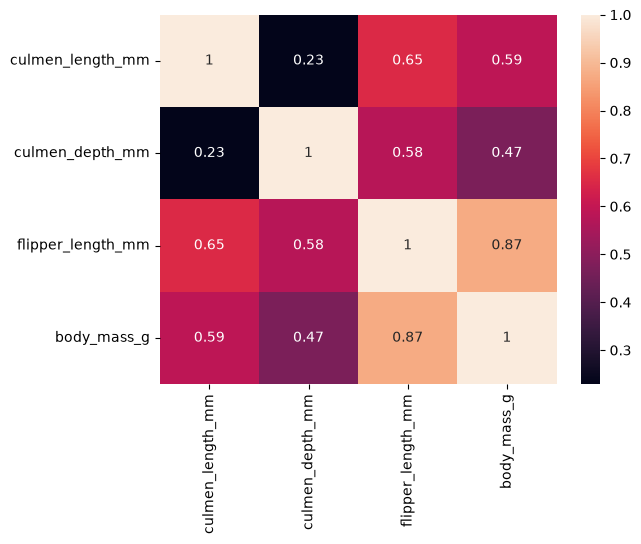

In [9]:
# Correlation between the measurements: flipper length and body mass are strongly correlated (0.87)
corr = np.abs(penguins.drop(columns=["species", "island", "sex"]).corr())
sns.heatmap(corr, annot=True)
plt.show()

In [10]:
# 4. Feature selection: the four body measurements
# Island is left out on purpose: Gentoos only live on Biscoe and Torgersen has only Adelies,
# so the model could guess from the location instead of the penguin.
target = penguins["species"]
features = penguins[["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]]

In [11]:
# 5. Train-test split (80/20)
x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.20, random_state=0)

In [12]:
# Normalization: scaler fitted on the training data only
scaler = MinMaxScaler()
scaler.fit(x_train)

x_train_scaled = pd.DataFrame(scaler.transform(x_train), columns=x_train.columns)
x_test_scaled = pd.DataFrame(scaler.transform(x_test), columns=x_test.columns)

In [13]:
# 6. Models: KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaled, y_train)
pred_knn = knn.predict(x_test_scaled)
print("KNN:", accuracy_score(y_test, pred_knn))

KNN: 0.9701492537313433


In [14]:
# Decision Tree
tree = DecisionTreeClassifier(max_depth=5, random_state=0)
tree.fit(x_train_scaled, y_train)
pred_tree = tree.predict(x_test_scaled)
print("Decision Tree:", accuracy_score(y_test, pred_tree))

Decision Tree: 0.9701492537313433


In [15]:
# 7. Ensemble models: Bagging
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                            max_samples=0.7, random_state=0)
bagging.fit(x_train_scaled, y_train)
pred_bagging = bagging.predict(x_test_scaled)
print("Bagging:", accuracy_score(y_test, pred_bagging))

Bagging: 0.9701492537313433


In [16]:
# Ensemble models: Random Forest
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(x_train_scaled, y_train)
pred_forest = forest.predict(x_test_scaled)
print("Random Forest:", accuracy_score(y_test, pred_forest))

Random Forest: 0.9701492537313433


In [17]:
# Ensemble models: AdaBoost
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                         n_estimators=100, random_state=0)
ada.fit(x_train_scaled, y_train)
pred_ada = ada.predict(x_test_scaled)
print("AdaBoost:", accuracy_score(y_test, pred_ada))

AdaBoost: 0.9552238805970149


In [18]:
# Ensemble models: Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, random_state=0)
gb.fit(x_train_scaled, y_train)
pred_gb = gb.predict(x_test_scaled)
print("Gradient Boosting:", accuracy_score(y_test, pred_gb))

Gradient Boosting: 0.9701492537313433


In [19]:
# Model comparison
# Five of six models reach 97% (2 wrong out of 67), AdaBoost 95.5%. Baseline: 44%.
# All models land in the same place, so the measurements do the work, not the algorithm.
results = pd.DataFrame({
    "Model": ["KNN", "Decision Tree", "Bagging", "Random Forest", "AdaBoost", "Gradient Boosting"],
    "Accuracy": [accuracy_score(y_test, p) for p in
                 [pred_knn, pred_tree, pred_bagging, pred_forest, pred_ada, pred_gb]]
}).sort_values("Accuracy", ascending=False)
results

,Model,Accuracy
0,KNN,0.970149
1,Decision Tree,0.970149
2,Bagging,0.970149
3,Random Forest,0.970149
5,Gradient Boosting,0.970149
4,AdaBoost,0.955224


In [20]:
# Feature importance (Random Forest): bill length is the most important feature
forest_importance = {feature: importance for feature, importance
                     in zip(x_train_scaled.columns, forest.feature_importances_)}
forest_importance

{'culmen_length_mm': np.float64(0.40053615303907836),
 'culmen_depth_mm': np.float64(0.23803657135307368),
 'flipper_length_mm': np.float64(0.29031982513377935),
 'body_mass_g': np.float64(0.07110745047406868)}

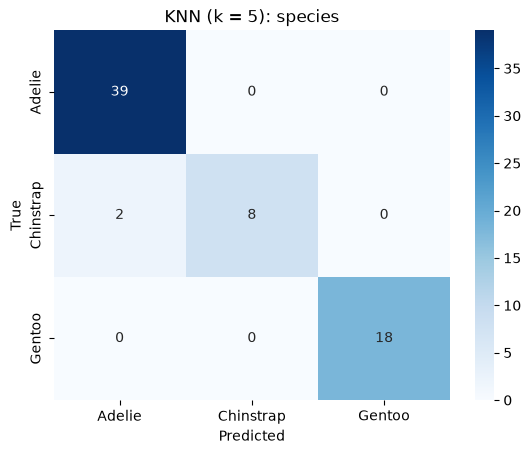

              precision    recall  f1-score   support

      Adelie       0.95      1.00      0.97        39
   Chinstrap       1.00      0.80      0.89        10
      Gentoo       1.00      1.00      1.00        18

    accuracy                           0.97        67
   macro avg       0.98      0.93      0.95        67
weighted avg       0.97      0.97      0.97        67



In [21]:
# 8. Wrong predictions: confusion map and classification report
# Chinstrap recall is only 0.80: the smallest class gets the errors.
species = ["Adelie", "Chinstrap", "Gentoo"]
plot_confusion_map(y_test, pred_knn, species, "KNN (k = 5): species")
print(classification_report(y_true=y_test, y_pred=pred_knn))

In [22]:
# 9. Hyperparameter tuning: Grid Search with 5-fold cross-validation
grid = {"n_neighbors": [3, 5, 7, 9, 11, 15],
        "weights": ["uniform", "distance"]}

model = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=grid, cv=5)
model.fit(x_train_scaled, y_train)

print(model.best_params_)
print("Cross-validation accuracy:", model.best_score_)

{'n_neighbors': 3, 'weights': 'uniform'}
Cross-validation accuracy: 0.9886792452830189


Tuned KNN: 0.9850746268656716


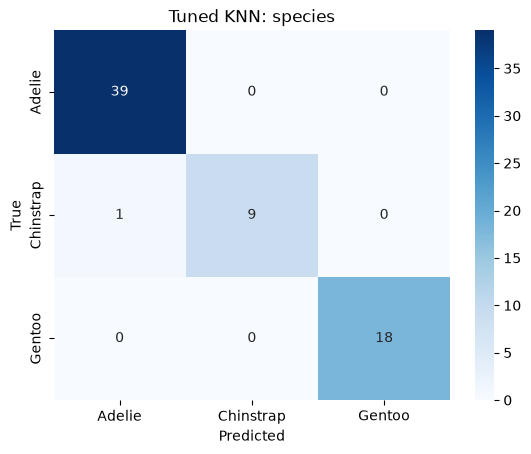

In [23]:
# Tuned model: k = 3 gives 98.5% on the test set, only 1 wrong (the Chinstrap with a 43.5 mm bill)
best_knn = model.best_estimator_
pred_best = best_knn.predict(x_test_scaled)
print("Tuned KNN:", accuracy_score(y_test, pred_best))

plot_confusion_map(y_test, pred_best, species, "Tuned KNN: species")

In [24]:
# 10. Additional test: predicting sex from the same four measurements
target_sex = penguins["sex"]
features_sex = penguins[["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]]

x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(features_sex, target_sex, test_size=0.20, random_state=0)

scaler_s = MinMaxScaler()
scaler_s.fit(x_train_s)
x_train_s_scaled = scaler_s.transform(x_train_s)
x_test_s_scaled = scaler_s.transform(x_test_s)

In [25]:
# Models for sex
knn_sex = KNeighborsClassifier(n_neighbors=5)
knn_sex.fit(x_train_s_scaled, y_train_s)
pred_knn_sex = knn_sex.predict(x_test_s_scaled)
print("KNN (sex):", accuracy_score(y_test_s, pred_knn_sex))

forest_sex = RandomForestClassifier(n_estimators=100, random_state=0)
forest_sex.fit(x_train_s_scaled, y_train_s)
pred_forest_sex = forest_sex.predict(x_test_s_scaled)
print("Random Forest (sex):", accuracy_score(y_test_s, pred_forest_sex))

KNN (sex): 0.9552238805970149
Random Forest (sex): 0.9552238805970149


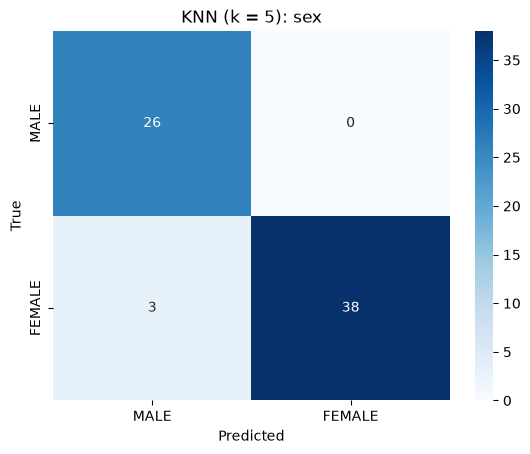

In [26]:
# Confusion map for sex: all 3 errors are large Adelie females predicted as male
plot_confusion_map(y_test_s, pred_knn_sex, ["MALE", "FEMALE"], "KNN (k = 5): sex")

In [27]:
# Grid Search for sex
# The test set says 95.5%, but cross-validation says about 90%. With only 67 test penguins
# (61% female), one penguin moves the score by 1.5 points, so 90% is the more honest number.
# Grid Search does not help: the limit is the information in the measurements, not the settings.
model_sex = GridSearchCV(estimator=KNeighborsClassifier(), param_grid=grid, cv=5)
model_sex.fit(x_train_s_scaled, y_train_s)

print(model_sex.best_params_)
print("Cross-validation accuracy:", model_sex.best_score_)
print("Tuned KNN (sex):", accuracy_score(y_test_s, model_sex.best_estimator_.predict(x_test_s_scaled)))

{'n_neighbors': 11, 'weights': 'distance'}
Cross-validation accuracy: 0.8988819007686931
Tuned KNN (sex): 0.9552238805970149


In [28]:
# 11. Conclusions
# - A score needs a baseline: 97% means something because guessing gives 44%.
# - Grid Search improved species KNN from 97.0% to 98.5% (k = 3).
# - The errors tell the story: they sit where Chinstraps and Adelies overlap.
# - Small data, careful numbers: cross-validation is more reliable than a single 67-penguin test set.